In [1]:
import networkx as nx
import os
import matplotlib.pyplot as plt
import matplotlib as mpl
from typing import List
import numpy as np

from graph_opt.community_detection import GraphLoader, NeighbourSampler, ExactEvaluator, SampleEvaluator, ExactWeightedEvaluator, SampleWeightedEvaluator, GreedyOptimizer, BruteForce, ExactOptimizer
from graph_community_detection.visualize import show_graph, get_layout

data_dir = 'data_toy'
# WEIGHTED re-run (ExactWeightedEvaluator / SampleWeightedEvaluator)
model_dir = 'models_opt/E2000_V20_T6/low_samples_weighted'
image_dir = 'images/optim_results_toy/low_samples_weighted'

if not os.path.exists(image_dir):
    os.makedirs(image_dir)

# Toy problem 1:

* Number of nodes $\left|\mathcal{V}\right|$: 20
* Number of edges $\left|\mathcal{E}\right|$: 2000
* Number of attributes $\left|\mathcal{T}\right|$: 6

The visualization of the graph is shown below

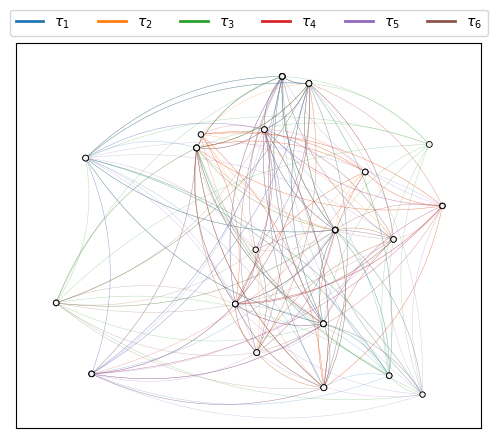

In [2]:
MG = nx.readwrite.graphml.read_graphml(os.path.join(data_dir,'test_airline_nodes_E2000_V20_T6.graphml')) # store graph

graph = GraphLoader(
    MG = MG,
    use_gpu = False
)

fig, ax = plt.subplots(figsize=(6, 5))

default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
selected_attrs = graph.attr_list  # The airlines you're interested in
edge_colors = [default_colors[i % len(default_colors)] for i in range(len(selected_attrs))]
# edge_colors = ['#FF0000', '#0000FF', '#00FF00', '#FF00FF', '#00FFFF', '#FFFF00', '#000000', '#FFFFFF']
legend_elements = []

for i,(airline,edge_color) in enumerate(zip(selected_attrs,edge_colors)):

    # Create a new undirected graph for the subgraph
    MG_reduced = nx.Graph()

    # First, handle the edge filtering and adding of node data
    for u, v, data in MG.edges(data=True):
        if data.get('edge_type') in [airline,]:
            # Add nodes along with their data if they haven't been added yet
            if not MG_reduced.has_node(u):
                MG_reduced.add_node(u, **MG.nodes[u])
            if not MG_reduced.has_node(v):
                MG_reduced.add_node(v, **MG.nodes[v])
            
            # Add or update the edge in the undirected graph
            if MG_reduced.has_edge(u, v) or MG_reduced.has_edge(v, u):
                if MG_reduced.has_edge(u, v):
                    MG_reduced[u][v]['weight'] += data.get('weight', 0)
                else:
                    MG_reduced[v][u]['weight'] += data.get('weight', 0)
            else:
                MG_reduced.add_edge(u, v, weight=data.get('weight', 0))

    # filter by average degree and standard deviation
    node_sizes = np.array(list(dict(nx.degree(MG_reduced, weight='weight')).values()))
    mean_deg = np.mean(np.log10(node_sizes+1e-6))
    std_deg = np.std(np.log10(node_sizes+1e-6))

    # set node sizes as attributes
    for n,d in MG_reduced.nodes(data=True):
        d['size'] = np.log10(nx.degree(MG_reduced, n, weight='weight')+1e-6)

    nodes = np.array(MG_reduced.nodes())[np.log10(node_sizes+1e-6) > 1.0*mean_deg].tolist()
    
    pos_rand = get_layout(MG_reduced,seed=43)

    # apply transparecy to edge color to get node color
    node_color = "#F2F2F2"

    show_graph(
        MG_reduced,
        ax=ax,
        nodes=nodes,
        n_largest=None,
        node_size='degree',
        node_size_scale=1,
        pos=pos_rand,
        show_edges=False,
        show_nodes=True,
        node_color=node_color,
    )

    show_graph(
        MG_reduced,
        ax=ax,
        nodes=nodes,
        n_largest=None,
        pos=pos_rand,
        show_edges=True,
        show_nodes=False,
        edge_color=edge_color,
        node_color=node_color,
        edge_alpha=0.4
    )
    
    legend_elements.append(mpl.lines.Line2D([0], [0], color=edge_color, label=r"$\tau_{%i}$" % (i+1), lw=2))

    ax.legend(handles=legend_elements, loc='lower center', bbox_to_anchor=(0.5, 1), ncol=6)

fig.savefig(os.path.join(image_dir,'toy_graph.pdf'), dpi=300, bbox_inches='tight', format='pdf')
fig.savefig(os.path.join(image_dir,'toy_graph.svg'), dpi=300, bbox_inches='tight', format='svg')

## loading the solutions

We load three solutions

* The exact solution given by: 

$\underset{x_{\tau,k}^*}{\text{maximize}} \bar{f} = -\beta\sum_{\left(u,v\right) \in \mathcal{E}} {h}_{u,v} + \gamma\sum_{\tau\in\mathcal{T}}\log{\left(\dfrac{1}{\left|\mathcal{V}\right|}\sum_{i\in\mathcal{V}}\sum_{k=1}^{K} \mathbf{1}_{\alpha_k}\left(\tau\right){p}(\alpha_k|i,L) \cdot {p}(\tau|i,L)\right)}$

We then obtain approximation of ${h}_{u,v}$, ${p}(\alpha_k|i,L)$, and ${p}(\tau|i,L)$ and use them to compute

* The greedy optimization solution 

$\underset{x_{\tau,k}^{*,\text{greedy}}}{\text{maximize}} \hat{f} = -\beta\sum_{\left(u,v\right) \in \mathcal{E}} \hat{h}_{u,v} + \gamma\sum_{\tau\in\mathcal{T}}\log{\left(\dfrac{1}{\left|\mathcal{V}\right|}\sum_{i\in\mathcal{V}}\sum_{k=1}^{K} \mathbf{1}_{\alpha_k}\left(\tau\right)\hat{p}(\alpha_k|i,L) \cdot \hat{p}(\tau|i,L)\right)}$

* The Exact optimization solution 

$\underset{x_{\tau,k}^{*,\text{exact}}}{\text{maximize}} \hat{f} = -\beta\sum_{\left(u,v\right) \in \mathcal{E}} \hat{h}_{u,v} + \gamma\sum_{\tau\in\mathcal{T}}\log{\left(\dfrac{1}{\left|\mathcal{V}\right|}\sum_{i\in\mathcal{V}}\sum_{k=1}^{K} \mathbf{1}_{\alpha_k}\left(\tau\right)\hat{p}(\alpha_k|i,L) \cdot \hat{p}(\tau|i,L)\right)}$

Here are the sampling parameters

| Parameter                         | Value     | Description                                           |
|-----------------------------------|-----------|-------------------------------------------------------|
| $\lvert\mathcal{N}_{u,v}\rvert$   | 50        | number of samples per edge (segment)                  |
| $n_\text{walks}$                  | 10        | number of random walks launched per node (airport)    |
| $L$                               | 2         | length of random walk                                 |
| $\beta$                           | 0.7       | weight of competition index objective                 |
| $\gamma$                          | 0.3       | weight of MPC objective                               |


In [3]:
exact_evaluator = ExactWeightedEvaluator(gloader=graph, walk_length=2)
brute_optimizer = BruteForce(evaluator=exact_evaluator, seed=None)

brute_optimizer.load(os.path.join(model_dir,"brute_force"))

  0%|          | 0/117649 [00:00<?, ?it/s]

 60%|█████▉    | 70436/117649 [00:00<00:00, 704353.95it/s]

100%|██████████| 117649/117649 [00:00<00:00, 735098.83it/s]

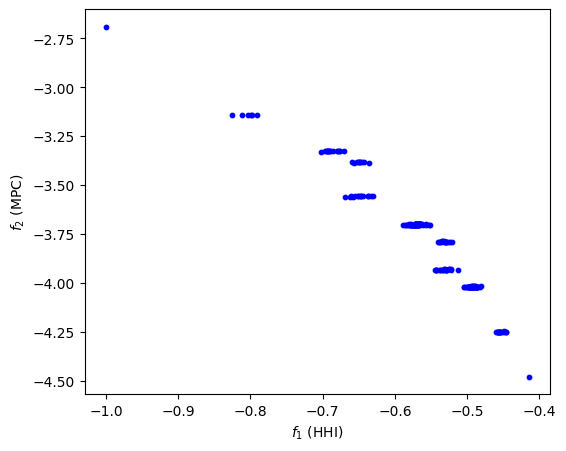

In [4]:
# plot Paretto frontier
x = []; y = []
for point in brute_optimizer.results_library.values():
    x.append(point["f1"]); y.append(point["f2"])

fig,ax = plt.subplots(figsize=(6,5))

ax.scatter(x, y, c='b', marker='o', label='Pareto frontier', s=10)
ax.set_xlabel('$f_1$ (HHI)')
ax.set_ylabel('$f_2$ (MPC)')
plt.show()

fig.savefig(os.path.join(image_dir,"pareto_frontier.pdf"), dpi=200, bbox_inches='tight')
fig.savefig(os.path.join(image_dir,"pareto_frontier.svg"), dpi=200, bbox_inches='tight')

In [5]:
N_SAMPLES = 10
WEIGHTS = (0.7,0.3)

greedy_opts:List[GreedyOptimizer] = []
for i_sample in range(N_SAMPLES):

    sampler_i = NeighbourSampler(gloader=graph)
    sample_evaluator_i = SampleWeightedEvaluator(gloader=graph,sampler=sampler_i)
    greedy_optimizer = GreedyOptimizer(evaluator=sample_evaluator_i,seed=i_sample)

    greedy_optimizer.load(os.path.join(model_dir,"greedy_optimizer_{}".format(i_sample)))
    greedy_opts.append(greedy_optimizer)

exact_opts:List[ExactOptimizer] = []
for i_sample in range(N_SAMPLES):

    sampler_i = NeighbourSampler(gloader=graph)
    sample_evaluator_i = SampleWeightedEvaluator(gloader=graph,sampler=sampler_i)

    model_path = os.path.join(model_dir,"exact_optimizer_{}".format(i_sample))
    exact_optimizer = ExactOptimizer(
        evaluator=sample_evaluator_i,
        seed=i_sample,
        weights=WEIGHTS,
        log_dir=model_path,
        log_interval=1,
    )

    exact_optimizer.load(model_path)
    exact_opts.append(exact_optimizer)

Set parameter Username


Academic license - for non-commercial use only - expires 2027-06-12


Read LP format model from file models_opt/E2000_V20_T6/low_samples_weighted/exact_optimizer_0/exact_optimizer.lp


Reading time = 0.00 seconds


: 12 rows, 54 columns, 48 nonzeros


...

Reading time = 0.00 seconds


: 12 rows, 54 columns, 48 nonzeros


Read LP format model from file models_opt/E2000_V20_T6/low_samples_weighted/exact_optimizer_9/exact_optimizer.lp


Reading time = 0.00 seconds


: 12 rows, 54 columns, 48 nonzeros


In [6]:
from collections import defaultdict
import tqdm

evaluator_compare = ExactWeightedEvaluator(gloader=graph, walk_length=2)

data_greedy = defaultdict(list)

with tqdm.tqdm(total=N_SAMPLES) as pbar:
    for i_sample, opt in enumerate(greedy_opts):

        x = opt.communities_history[-1]

        evaluator_compare.update_scores(x)

        f1 = -np.mean(list(evaluator_compare.hhi.values()))
        f2 = np.mean(list(evaluator_compare.log_mpc.values()))

        f = WEIGHTS[0]*f1 + WEIGHTS[1]*f2
            
        data_greedy["f1"].append(f1)
        data_greedy["f2"].append(f2)
        data_greedy["f"].append(f)

        pbar.update(1)

data_exact = defaultdict(list)

with tqdm.tqdm(total=N_SAMPLES) as pbar:
    for i_sample, opt in enumerate(exact_opts):

        x = opt.communities_history[-1]

        evaluator_compare.update_scores(x)

        f1 = -np.mean(list(evaluator_compare.hhi.values()))
        f2 = np.mean(list(evaluator_compare.log_mpc.values()))

        f = WEIGHTS[0]*f1 + WEIGHTS[1]*f2
            
        data_exact["f1"].append(f1)
        data_exact["f2"].append(f2)
        data_exact["f"].append(f)

        pbar.update(1)

  0%|          | 0/10 [00:00<?, ?it/s]

 10%|█         | 1/10 [00:00<00:05,  1.67it/s]

 20%|██        | 2/10 [00:00<00:02,  2.67it/s]

 30%|███       | 3/10 [00:01<00:02,  3.16it/s]

 40%|████      | 4/10 [00:01<00:01,  3.56it/s]

...

 70%|███████   | 7/10 [00:01<00:00,  4.58it/s]

 80%|████████  | 8/10 [00:01<00:00,  4.61it/s]

 90%|█████████ | 9/10 [00:01<00:00,  4.66it/s]

100%|██████████| 10/10 [00:02<00:00,  4.68it/s]

100%|██████████| 10/10 [00:02<00:00,  4.61it/s]

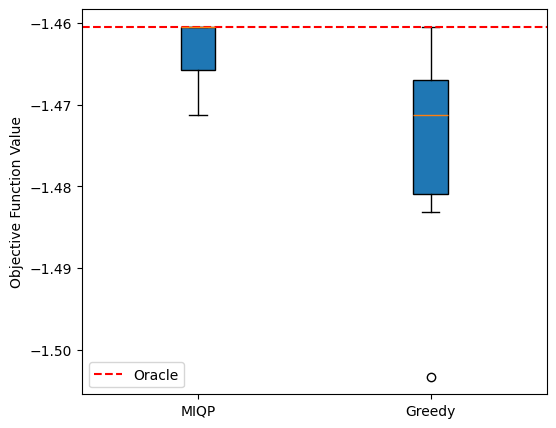

In [7]:
# Create the boxplot
fig,ax = plt.subplots(figsize=(6,5))
ax.boxplot([data_exact["f"], data_greedy["f"]], patch_artist=True)

# Adding horizontal line
ax.axhline(y=brute_optimizer.f_history[-1], color='r', linestyle='--', label='Oracle')

# Add some plot decorations
ax.set_ylabel('Objective Function Value')
ax.set_xticklabels(['MIQP', 'Greedy'])
ax.legend()

# Show the plot
plt.show()
fig.savefig(os.path.join(image_dir,"comparison_exact_greedy.pdf"),dpi=200, bbox_inches='tight')
fig.savefig(os.path.join(image_dir,"comparison_exact_greedy.svg"),dpi=200, bbox_inches='tight')

# Optimization performance study

We investigate the the MIP progress of one of the exact models and the tradeoff in one of the greedy models below

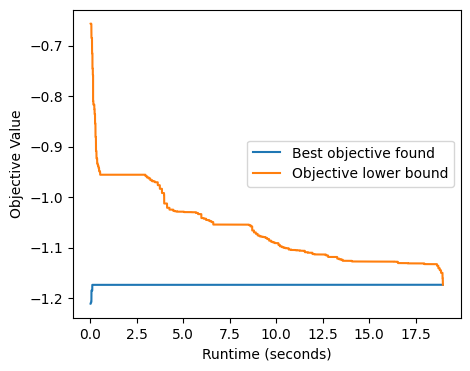

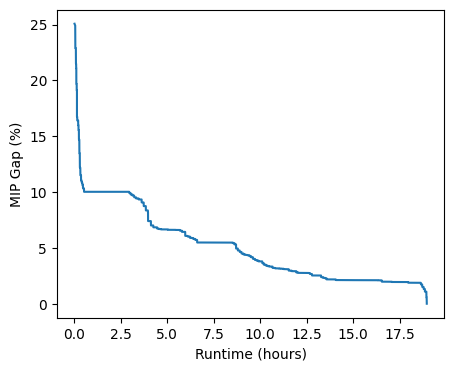

In [8]:
from matplotlib import axis
import pandas as pd

data = pd.read_csv(os.path.join(model_dir,"exact_optimizer_{}".format(0),"mip_solution.csv"))

time_data = data[data.columns[0]].loc[5:]
obj_data = data[data.columns[1]].loc[5:]
lb_data = data[data.columns[2]].loc[5:]
mip_data = data[data.columns[3]].loc[5:] * 100

# Create a new figure and set the size
fig_obj,ax = plt.subplots(figsize=(5, 4))
ax.plot(time_data, obj_data, label='Best objective found')
ax.plot(time_data, lb_data, label='Objective lower bound')
ax.set_xlabel('Runtime (seconds)')
ax.set_ylabel('Objective Value')
ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))

ax.legend(loc='right', fontsize=10)
plt.show()

# Create a new figure and set the size
fig_gap,ax = plt.subplots(figsize=(5, 4))
ax.plot(time_data, mip_data)
ax.set_xlabel('Runtime (hours)')
ax.set_ylabel('MIP Gap (%)')
plt.show()

fig_obj.savefig(os.path.join(image_dir,'obj_plot.pdf'), format='pdf', dpi=200, bbox_inches='tight')
fig_gap.savefig(os.path.join(image_dir,'gap_plot.pdf'), format='pdf', dpi=200, bbox_inches='tight')
fig_obj.savefig(os.path.join(image_dir,'obj_plot.svg'), format='svg', dpi=200, bbox_inches='tight')
fig_gap.savefig(os.path.join(image_dir,'gap_plot.svg'), format='svg', dpi=200, bbox_inches='tight')

And below we investigate the tradeoff progress of the greedy algorithm

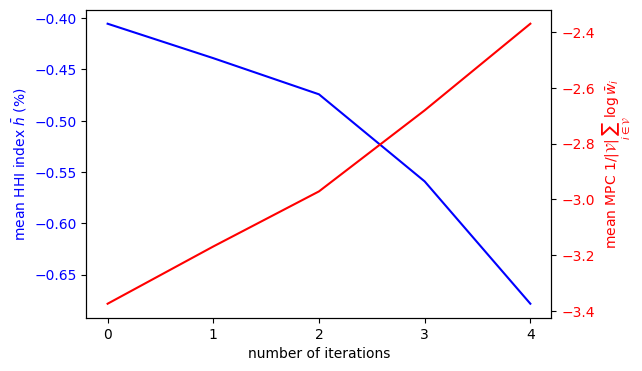

In [9]:
x_data = [i for i in range(len(greedy_optimizer.multi_history))]
y1_data = [f1 for f1,f2 in greedy_optimizer.multi_history]
y2_data = [f2 for f1,f2 in greedy_optimizer.multi_history]

# Create figure and axes
fig, ax1 = plt.subplots(figsize=(6, 4))

# Plot the first data on the first axis
ax1.plot(x_data, y1_data, color='blue')
ax1.set_xlabel('number of iterations')
ax1.set_ylabel(r'mean HHI index $\bar{h}$ ($\%$)', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_xticks([i for i in range(len(greedy_optimizer.multi_history))])
ax1.set_xticklabels([str(i) for i in range(len(greedy_optimizer.multi_history))])

# Create a second axis sharing the same x-axis
ax2 = ax1.twinx()

# Plot the second data on the second axis
ax2.plot(x_data, y2_data, color='red')
ax2.set_ylabel(r'mean MPC $1/{|\mathcal{V}|}\sum_{i\in\mathcal{V}}\log{\bar{w}_i}$', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Show the plot
plt.show()
fig.savefig(os.path.join(image_dir,'convergence.pdf'), format='pdf', dpi=200, bbox_inches='tight')
fig.savefig(os.path.join(image_dir,'convergence.svg'), format='svg', dpi=200, bbox_inches='tight')

In [10]:
from typing import Dict

def get_median(data):
    sorted_f = sorted(data)
    median_f = sorted_f[len(sorted_f) // 2 - 1]
    median_index = data.index(median_f)
    return median_f, median_index

median_f_exact, median_index_exact = get_median(data_exact["f"])
median_f_greedy, median_index_greedy = get_median(data_greedy["f"])

print("Optimal exact solution: ", exact_opts[median_index_exact].communities_history[-1])
print("Optimal exact objective: ", exact_opts[median_index_exact].f_history[-1])
print("Optimal exact objectives: ", exact_opts[median_index_exact].multi_history[-1])

print("Optimal greedy solution: ", greedy_opts[median_index_greedy].communities_history[-1])
print("Optimal greedy objective: ", greedy_opts[median_index_greedy].f_history[-1])
print("Optimal greedy objectives: ", greedy_opts[median_index_greedy].multi_history[-1])

print("Oracle solution: ", brute_optimizer.communities_history[-1])
print("Oracle objective: ", brute_optimizer.f_history[-1])
print("Oracle objectives: ", brute_optimizer.multi_history[-1])

def get_communities(communities_dict:Dict[str,int]) -> Dict[int,List[str]]:
    communities = defaultdict(list)
    for node, comm in communities_dict.items():
        communities[comm].append(node)
    return communities

attr_2_index = {attr:i+1 for i,attr in enumerate(graph.attr_list)}

communities_exact = get_communities(exact_opts[median_index_exact].communities_history[-1])
communities_greedy = get_communities(greedy_opts[median_index_greedy].communities_history[-1])
communities_brute = get_communities(brute_optimizer.communities_history[-1])

print("Exact communities: ", {comm+1:[attr_2_index[attr] for attr in members] for comm,members in communities_exact.items()})
print("Greedy communities: ", {comm+1:[attr_2_index[attr] for attr in members] for comm,members in communities_greedy.items()})
print("Brute communities: ", {comm+1:[attr_2_index[attr] for attr in members] for comm,members in communities_brute.items()})

Optimal exact solution:  {'AA': 5, 'AB': 4, 'AC': 5, 'AD': 5, 'AE': 4, 'AF': 4}
Optimal exact objective:  -1.166526597738266
Optimal exact objectives:  [-0.628985583782196, -2.4207889636357627]
Optimal greedy solution:  {'AA': 0, 'AB': 0, 'AC': 0, 'AD': 0, 'AE': 4, 'AF': 4}
Optimal greedy objective:  -1.185767376422882
Optimal greedy objectives:  [-0.678442656993866, -2.369525055090586]
Oracle solution:  {'AA': 0, 'AB': 1, 'AC': 0, 'AD': 0, 'AE': 1, 'AF': 1}
Oracle objective:  -1.4604668498039244
Oracle objectives:  [-0.6358455419540405, -3.3845832347869873]
Exact communities:  {6: [1, 3, 4], 5: [2, 5, 6]}
Greedy communities:  {1: [1, 2, 3, 4], 5: [5, 6]}
Brute communities:  {1: [1, 3, 4], 2: [2, 5, 6]}


We also display the greedy and exact solutions on the Pareto frontier of all possible solutions

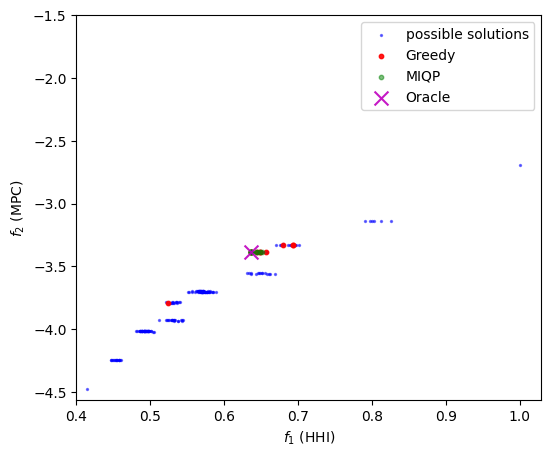

In [11]:
# plot Paretto frontier
x = []; y = []
for point in brute_optimizer.results_library.values():
    x.append(-point["f1"]); y.append(point["f2"])

fig,ax = plt.subplots(figsize=(6,5))

ax.scatter(x, y, c='b', marker='o', label='possible solutions', s=2, alpha=0.5)
ax.scatter([-x for x in data_greedy["f1"]], data_greedy["f2"], c='r', marker='o', label='Greedy', s=10, alpha=0.9)
ax.scatter([-x for x in data_exact["f1"]], data_exact["f2"], c='g', marker='o', label='MIQP', s=10, alpha=0.5)
ax.scatter(-brute_optimizer.multi_history[-1][0], brute_optimizer.multi_history[-1][1], c='m', marker='x', label='Oracle', s=100, alpha=0.9)
ax.set_xlabel('$f_1$ (HHI)')
ax.set_ylabel('$f_2$ (MPC)')
ax.set_xlim([0.4,ax.get_xlim()[1]])
ax.set_ylim([ax.get_ylim()[0],-1.5])
ax.legend()
plt.show()

fig.savefig(os.path.join(image_dir,"pareto_frontier.pdf"), dpi=200, bbox_inches='tight')
fig.savefig(os.path.join(image_dir,"pareto_frontier.svg"), dpi=200, bbox_inches='tight')